In [1]:
%matplotlib widget
import numpy as np
import tomllib
from pathlib import Path

from thesis_code.plotting import plot_performance, plot_gradients, plot_weight_matrices, InteractiveSpikePlot

In [2]:
work_dir = Path.cwd()
print(work_dir)
with open(work_dir / "config.toml", 'rb') as cfg_file:
    cfg = tomllib.load(cfg_file)

n_trials = cfg["training"]["n_trials"]
# def get_data(data_group: str, data_name: str) -> np.ndarray:
    # return np.array([np.load(work_dir / f"seed_{i}" / "data_net" / data_group / data_name) for i in range(n_trials)])

c:\Users\emiel\Documents\Study\Thesis\Thesis-Code\outputs\2026-10-14_14-38-04-test_recorder_speed_speedup


In [44]:
def load_recording(data_name: str, key: str) -> np.ndarray:
    data = []
    for i in range(n_trials):
        with np.load(work_dir / f"seed_{i}" / "data_net" / f"{data_name}.npz") as d:
            data.append(d[key])
    return np.array(data)

def get_data(data_name: str) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_0" / "data_net" / f"{data_name}.npz") as d:
        keys = list(d.keys())
    return {key: load_recording(data_name, key) for key in keys}

def get_data_seed(data_name: str, seed: int) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_{seed}" / "data_net" / f"{data_name}.npz") as d:
        return {key: d[key] for key in list(d.keys())}

(3, 1)


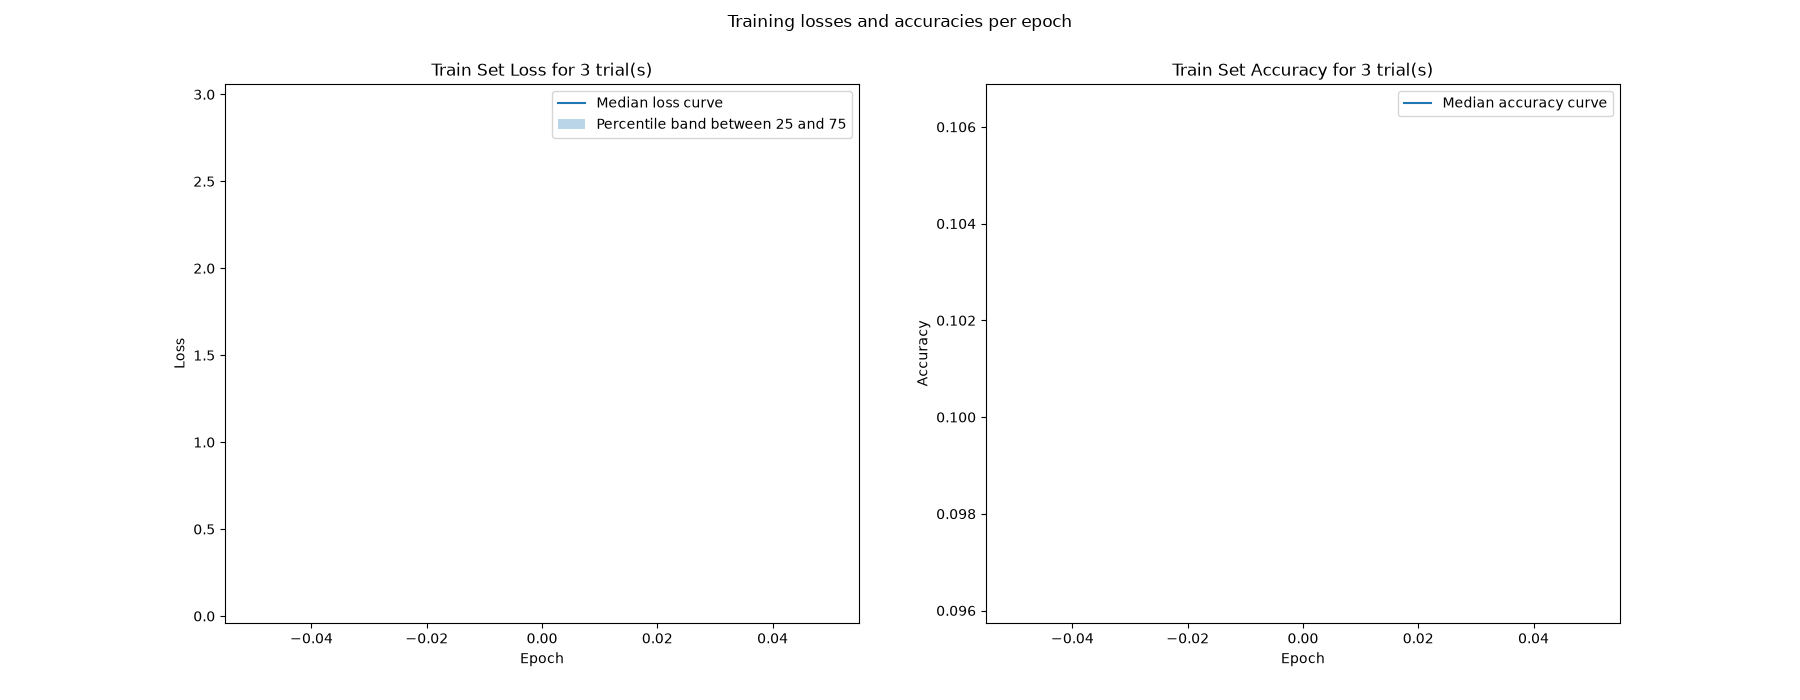

In [ ]:
perf_data = get_data("performance")
plot_performance(perf_data["loss"], perf_data["acc"])

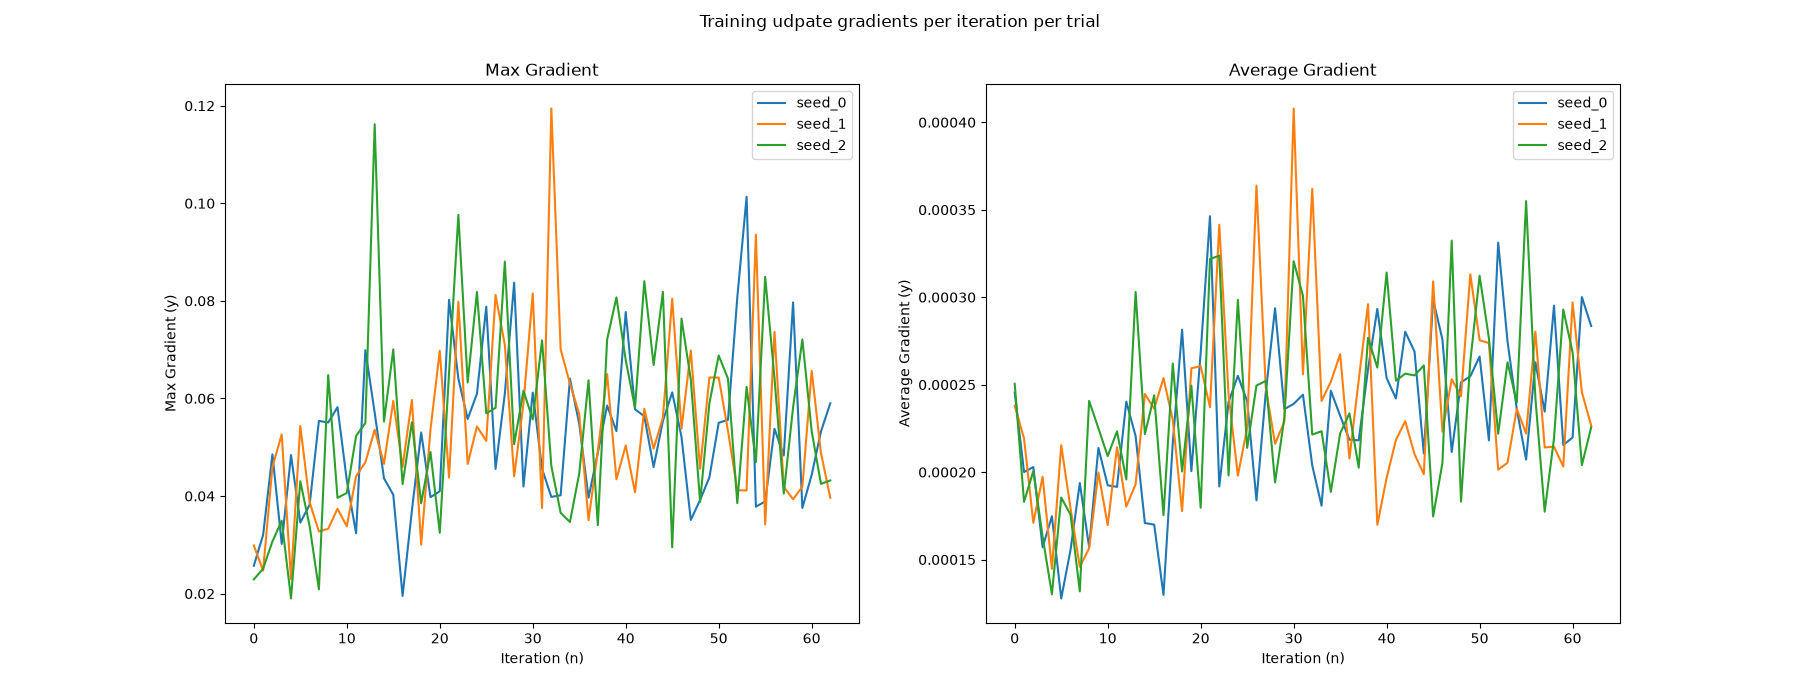

In [36]:
grad_data = get_data("gradients")
plot_gradients(grad_data["max_grad"], grad_data["avg_grad"])

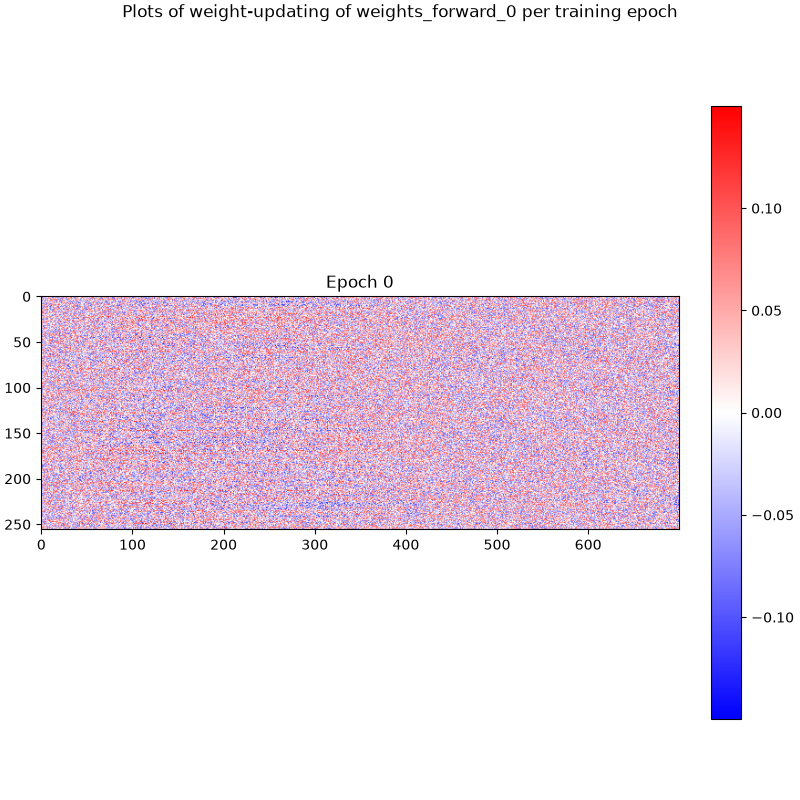

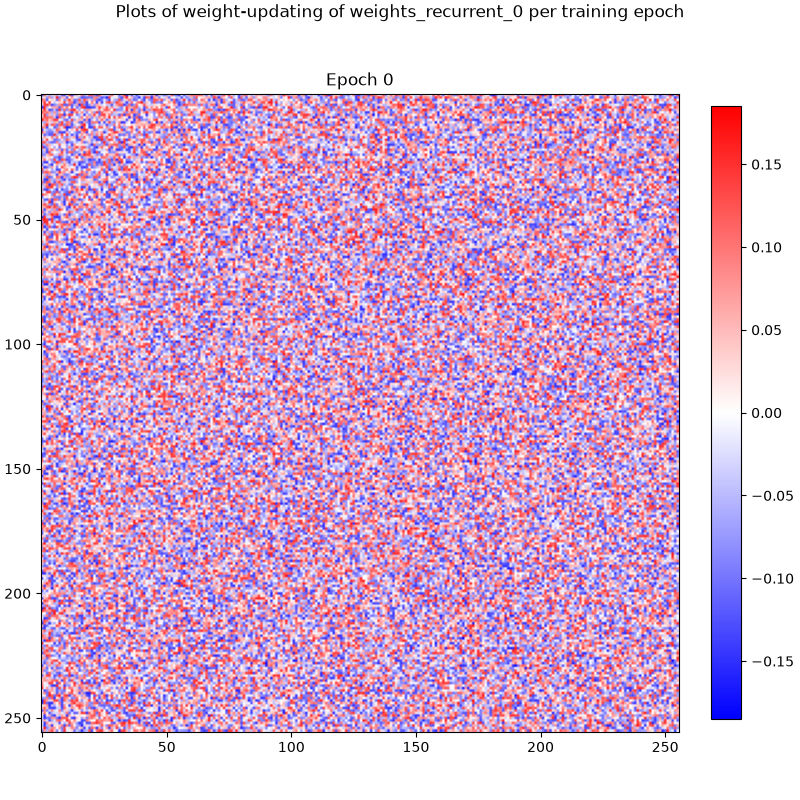

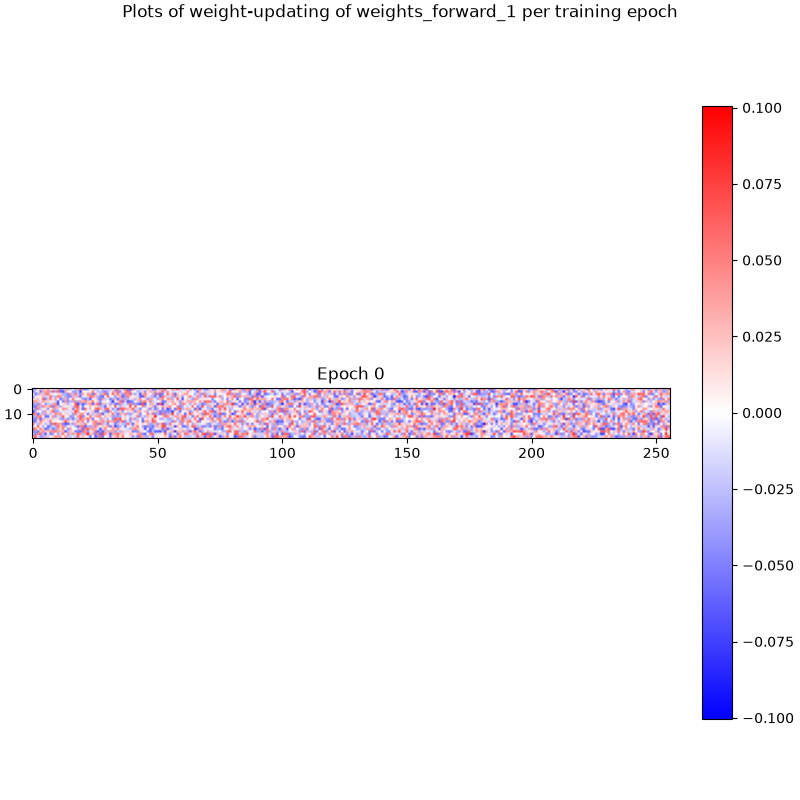

In [40]:
for key, data in get_data("weights").items():
    plot_weight_matrices(data, name=key)

dict_keys(['spikes_in-n_cols', 'spikes_in', 'mems_out', 'targets', 'spikes_hidden_0-n_cols', 'spikes_hidden_0'])


IndexError: too many indices for array: array is 0-dimensional, but 3 were indexed

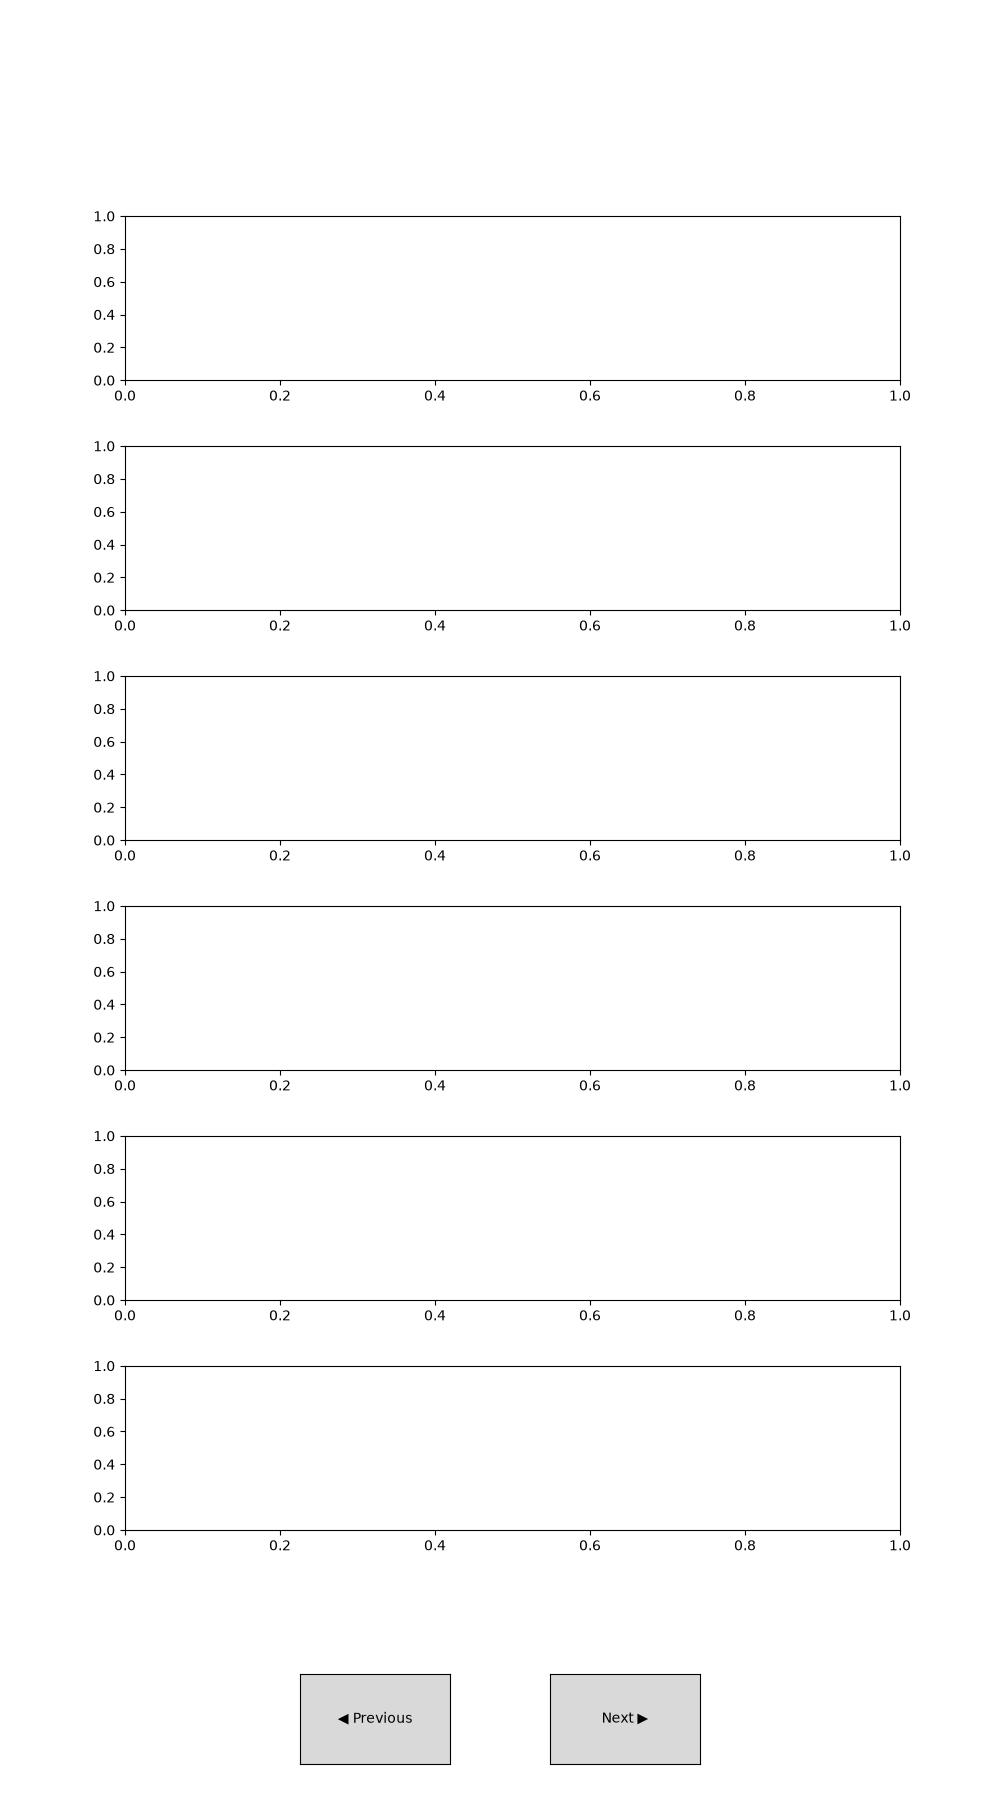

In [48]:
layer_spikes = get_data_seed("spikes", seed=0)
print(layer_spikes.keys())
isp = InteractiveSpikePlot(layer_spikes, range(1, 21))
isp.draw()
# isp.save_as_pdf()


# layer_spikes = {
#     "spikes_in": get_data("spikes", "spikes_in")[0],
#     "spikes_hidden_0": get_data("spikes", "spikes_hidden_0")[0],
#     "spikes_out": get_data("spikes", "spikes_out")[0],
#     "targets": get_data("spikes", "targets")[0],
# }
# isp = InteractiveSpikePlot(layer_spikes, range(1, 21))
# isp.draw()
# isp.save_as_pdf()